In [5]:
import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.colab import files

# Set style for visualizations
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# 1. Trigger the upload widget
uploaded = files.upload()

# 2. Get the filename dynamically
filename = list(uploaded.keys())[0]

# 3. Load the dataset into a Pandas DataFrame
df = pd.read_csv(io.BytesIO(uploaded[filename]))

# 4. Display basic structural information
df.info()
df.head()


Saving retail_sales_dataset.csv to retail_sales_dataset (1).csv
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [6]:
# 1. Check for missing values and display the result
print("--- Missing Values Count per Column ---")
missing_counts = df.isnull().sum()
print(missing_counts)

# 2. Check for completely duplicate rows and display the count
print("\n--- Duplicate Rows Count ---")
duplicate_count = df.duplicated().sum()
print(f"Number of completely duplicated rows: {duplicate_count}")

# 3. Handle missing values: Fill numerical columns with mean, categorical with mode
for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype in ["int64", "float64"]:
            df[col] = df[col].fillna(df[col].mean())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

# 4. Handle duplicate records: Remove rows only if the entire row is repeated
df = df.drop_duplicates(keep="first")

# 5. Verify the data is clean
print("\n--- Post-Cleaning Verification ---")
print(f"Remaining missing values: {df.isnull().sum().sum()}")
print(f"Remaining duplicate rows: {df.duplicated().sum()}")
print(f"Cleaned dataset shape: {df.shape}")


--- Missing Values Count per Column ---
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

--- Duplicate Rows Count ---
Number of completely duplicated rows: 0

--- Post-Cleaning Verification ---
Remaining missing values: 0
Remaining duplicate rows: 0
Cleaned dataset shape: (1000, 9)


In [7]:
# 1. Standardize string columns (convert to small case and trim whitespaces)
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].astype(str).str.lower().str.strip()

# 2. Modify Transaction ID: Add "t" in front of the value if not already present
df["Transaction ID"] = df["Transaction ID"].apply(
    lambda x: f"t{x}" if not str(x).startswith("t") else x
)

# 3. Standardize Gender: Convert "male" to "M" and "female" to "F"
df["Gender"] = df["Gender"].map({"male": "M", "female": "F"}).fillna(df["Gender"])

# 4. Handle Age: Ensure positive whole numbers (absolute value and convert to integer)
df["Age"] = df["Age"].abs().astype(int)

# 5. Handle Quantity: Take absolute value for negatives, drop decimal part for floats
df["Quantity"] = df["Quantity"].abs().astype(int)

# 6. Handle Price per Unit: Ensure positive value using absolute/mod value
df["Price per Unit"] = df["Price per Unit"].abs()

# 7. Recalculate Total Amount: Ensure exact adherence to formula (Quantity * Price per Unit)
df["Total Amount"] = df["Quantity"] * df["Price per Unit"]

# Display the first 10 records
df.head(10)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,t1,2023-11-24,cust001,M,34,beauty,3,50,150
1,t2,2023-02-27,cust002,F,26,clothing,2,500,1000
2,t3,2023-01-13,cust003,M,50,electronics,1,30,30
3,t4,2023-05-21,cust004,M,37,clothing,1,500,500
4,t5,2023-05-06,cust005,M,30,beauty,2,50,100
5,t6,2023-04-25,cust006,F,45,beauty,1,30,30
6,t7,2023-03-13,cust007,M,46,clothing,2,25,50
7,t8,2023-02-22,cust008,M,30,electronics,4,25,100
8,t9,2023-12-13,cust009,M,63,electronics,2,300,600
9,t10,2023-10-07,cust010,F,52,clothing,4,50,200


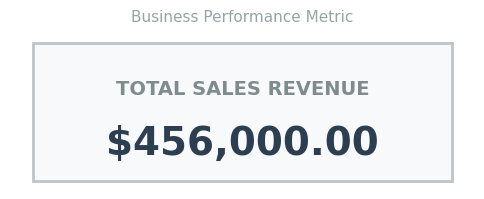

In [9]:
# =========================================================================
# 1. SCORECARD: DISPLAY TOTAL SALES (TOTAL AMOUNT SUM)
# =========================================================================
total_sales = df["Total Amount"].sum()

fig, ax = plt.subplots(figsize=(6, 2))
ax.axis("off")  # Turn off standard plot borders and axes

# Draw a clean box container for the scorecard (using standard Rectangle)
ax.add_patch(
    plt.Rectangle(
        (0.05, 0.05),
        0.9,
        0.9,
        transform=ax.transAxes,
        facecolor="#f8f9fa",
        edgecolor="#bdc3c7",
        linewidth=2,
    )
)

# Text placement within the scorecard box
ax.text(
    0.5,
    0.65,
    "TOTAL SALES REVENUE",
    fontsize=14,
    fontweight="bold",
    color="#7f8c8d",
    ha="center",
    va="center",
)
ax.text(
    0.5,
    0.3,
    f"${total_sales:,.2f}",
    fontsize=28,
    fontweight="bold",
    color="#2c3e50",
    ha="center",
    va="center",
)

plt.title("Business Performance Metric", fontsize=11, color="#95a5a6", pad=10)
plt.show()


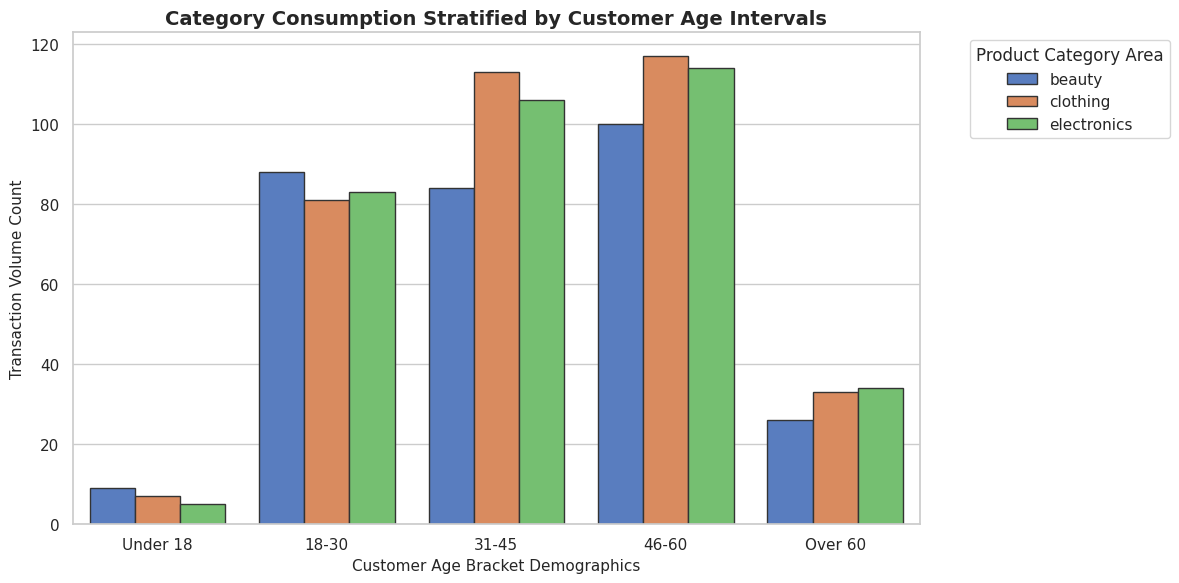

In [10]:
# =========================================================================
# 5. CUSTOMER PROFILE: AGE INTERVAL DISTRIBUTION PER CATEGORY
# =========================================================================
# Segregate demographic ages into categorical intervals using completed bins
age_bins = [0, 18, 30, 45, 60, 100]
age_labels = ["Under 18", "18-30", "31-45", "46-60", "Over 60"]
df["Age Interval"] = pd.cut(df["Age"], bins=age_bins, labels=age_labels)

# Extract total purchase activity across demographic groups and product categories
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df,
    x="Age Interval",
    hue="Product Category",
    palette="muted",
    edgecolor="0.2",
)

plt.title("Category Consumption Stratified by Customer Age Intervals", fontsize=14, fontweight="bold")
plt.xlabel("Customer Age Bracket Demographics", fontsize=11)
plt.ylabel("Transaction Volume Count", fontsize=11)
plt.legend(title="Product Category Area", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


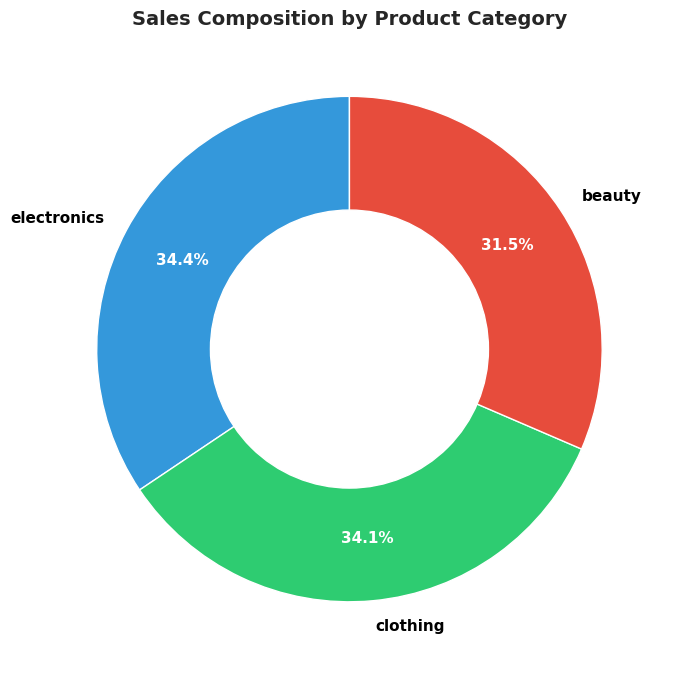

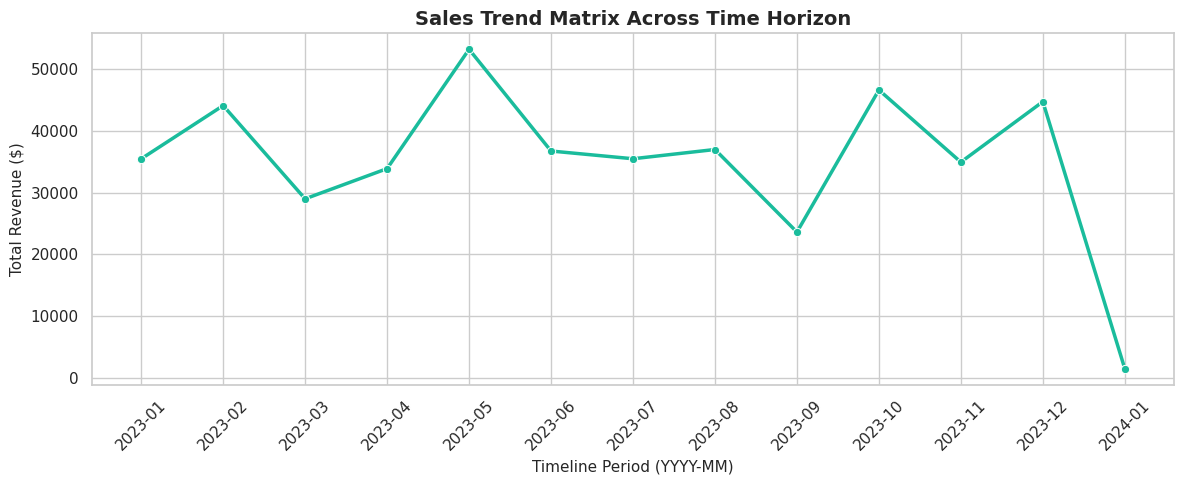

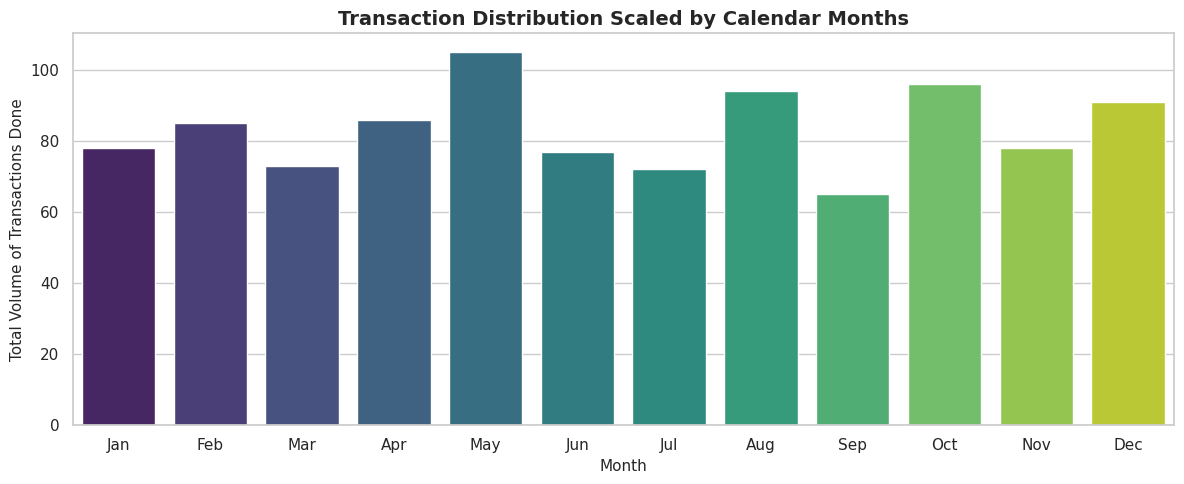

In [11]:
category_sales = (
    df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)
)

plt.figure(figsize=(7, 7))
colors = ["#3498db", "#2ecc71", "#e74c3c", "#f1c40f", "#9b59b6"]

# Generate a standard pie chart first
wedges, texts, autotexts = plt.pie(
    category_sales,
    labels=category_sales.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors[: len(category_sales)],
    pctdistance=0.75,
    textprops=dict(color="black", weight="bold"),
)

# Style percentages text cleanly
for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_fontsize(11)

# Draw a clean white circle in the middle to transform it into a donut chart
centre_circle = plt.Circle((0, 0), 0.55, fc="white")
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title("Sales Composition by Product Category", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


# =========================================================================
# 3. LINE CHART: TREND ANALYSIS ACROSS THE YEAR (MONTHLY REVENUE TRAJECTORY)
# =========================================================================
# Group by Year-Month to capture progression over the time horizon
monthly_trends = (
    df.groupby("Year-Month")["Total Amount"].sum().reset_index()
)
monthly_trends["Year-Month"] = monthly_trends["Year-Month"].astype(str)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_trends,
    x="Year-Month",
    y="Total Amount",
    marker="o",
    linewidth=2.5,
    color="#1abc9c",
)

plt.title("Sales Trend Matrix Across Time Horizon", fontsize=14, fontweight="bold")
plt.xlabel("Timeline Period (YYYY-MM)", fontsize=11)
plt.ylabel("Total Revenue ($)", fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# =========================================================================
# 4. BAR CHART: MONTH-WISE TRANSACTION ANALYSIS
# =========================================================================
# Generate an ordered baseline calendar to prevent disordered month plotting
month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Quantify total unique order counts (Transactions done) per Month
monthly_transactions = (
    df.groupby("Month")["Transaction ID"].count().reindex(month_order).reset_index()
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=monthly_transactions,
    x="Month",
    y="Transaction ID",
    hue="Month",
    palette="viridis",
    legend=False,
)

plt.title("Transaction Distribution Scaled by Calendar Months", fontsize=14, fontweight="bold")
plt.xlabel("Month", fontsize=11)
plt.ylabel("Total Volume of Transactions Done", fontsize=11)
plt.tight_layout()
plt.show()



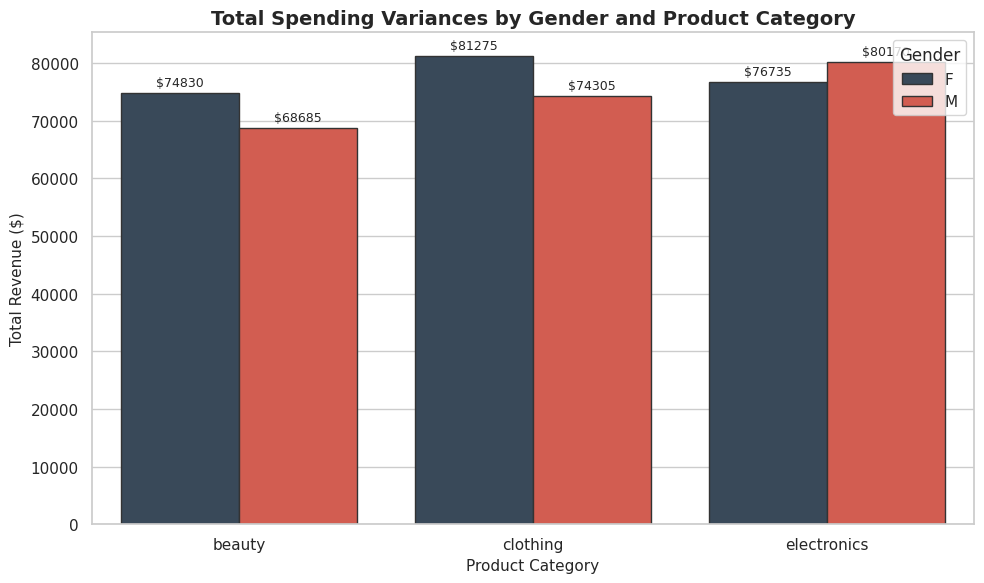

In [12]:
# =========================================================================
# 6. GENDER PROFILES: TOTAL SPENDING DISTRIBUTION BY PRODUCT CATEGORY
# =========================================================================
# Aggregate total amount spent by gender and product category
gender_spending = (
    df.groupby(["Product Category", "Gender"])["Total Amount"].sum().reset_index()
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=gender_spending,
    x="Product Category",
    y="Total Amount",
    hue="Gender",
    palette=["#34495e", "#e74c3c"],  # Professional distinct colors for M and F
    edgecolor="0.2",
)

plt.title("Total Spending Variances by Gender and Product Category", fontsize=14, fontweight="bold")
plt.xlabel("Product Category", fontsize=11)
plt.ylabel("Total Revenue ($)", fontsize=11)
plt.legend(title="Gender", loc="upper right")

# Add value labels on top of the bars for crisp readability
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="$%.0f", label_type="edge", padding=3, fontsize=9)

plt.tight_layout()
plt.show()


--- Product Category Structural Metrics ---
Product Category Total_Sales  Total_Transactions Avg_Price_Per_Unit Average Order Value (AOV)
          beauty $143,515.00                 307            $184.06                   $467.48
        clothing $155,580.00                 351            $174.29                   $443.25
     electronics $156,905.00                 342            $181.90                   $458.79


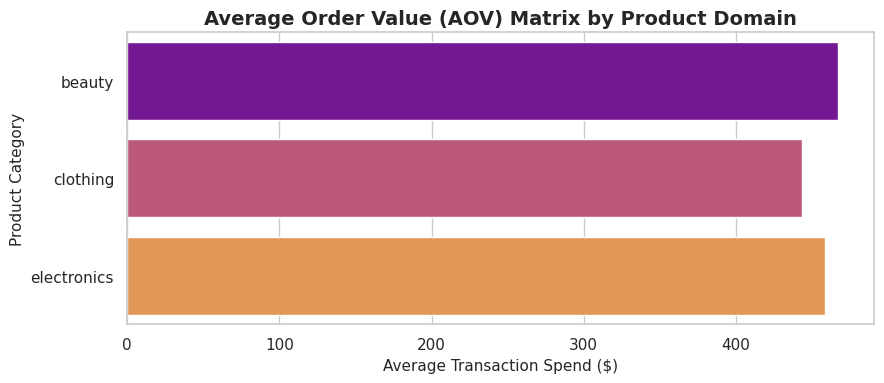

In [13]:
# =========================================================================
# 7. METRIC BOARD: AVERAGE ORDER VALUE (AOV) BY PRODUCT CATEGORY
# =========================================================================
# Calculate total sales, total transactions, and AOV per product domain
category_metrics = df.groupby("Product Category").agg(
    Total_Sales=("Total Amount", "sum"),
    Total_Transactions=("Transaction ID", "count"),
    Avg_Price_Per_Unit=("Price per Unit", "mean")
).reset_index()

category_metrics["Average Order Value (AOV)"] = (
    category_metrics["Total_Sales"] / category_metrics["Total_Transactions"]
)

# Display numerical summary table directly in Colab output
print("--- Product Category Structural Metrics ---")
print(category_metrics.to_string(index=False, formatters={
    "Total_Sales": "${:,.2f}".format,
    "Avg_Price_Per_Unit": "${:,.2f}".format,
    "Average Order Value (AOV)": "${:,.2f}".format
}))

# Visualize AOV using a clean horizontal bar chart
plt.figure(figsize=(9, 4))
sns.barplot(
    data=category_metrics,
    x="Average Order Value (AOV)",
    y="Product Category",
    hue="Product Category",
    palette="plasma",
    legend=False
)

plt.title("Average Order Value (AOV) Matrix by Product Domain", fontsize=14, fontweight="bold")
plt.xlabel("Average Transaction Spend ($)", fontsize=11)
plt.ylabel("Product Category", fontsize=11)
plt.tight_layout()
plt.show()


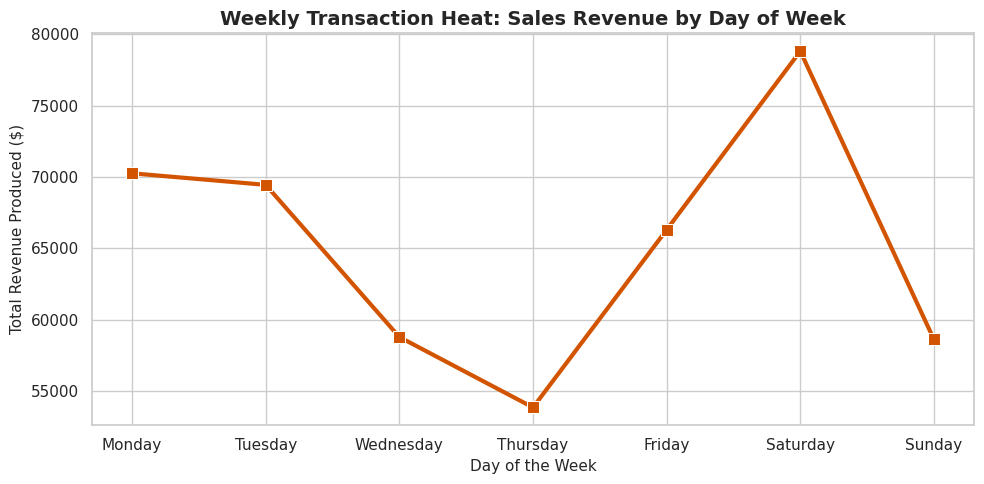

In [14]:
# =========================================================================
# 8. TIME TREND: DAY-OF-WEEK SALES TRAJECTORY
# =========================================================================
# Extract named days of the week from the Date timeline
df["Day of Week"] = df["Date"].dt.day_name()

# Order calendar days chronologically to keep the chart axis clean
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_sales = df.groupby("Day of Week")["Total Amount"].sum().reindex(day_order).reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=weekday_sales,
    x="Day of Week",
    y="Total Amount",
    marker="s",
    markersize=8,
    linewidth=3,
    color="#d35400"
)

plt.title("Weekly Transaction Heat: Sales Revenue by Day of Week", fontsize=14, fontweight="bold")
plt.xlabel("Day of the Week", fontsize=11)
plt.ylabel("Total Revenue Produced ($)", fontsize=11)
plt.tight_layout()
plt.show()


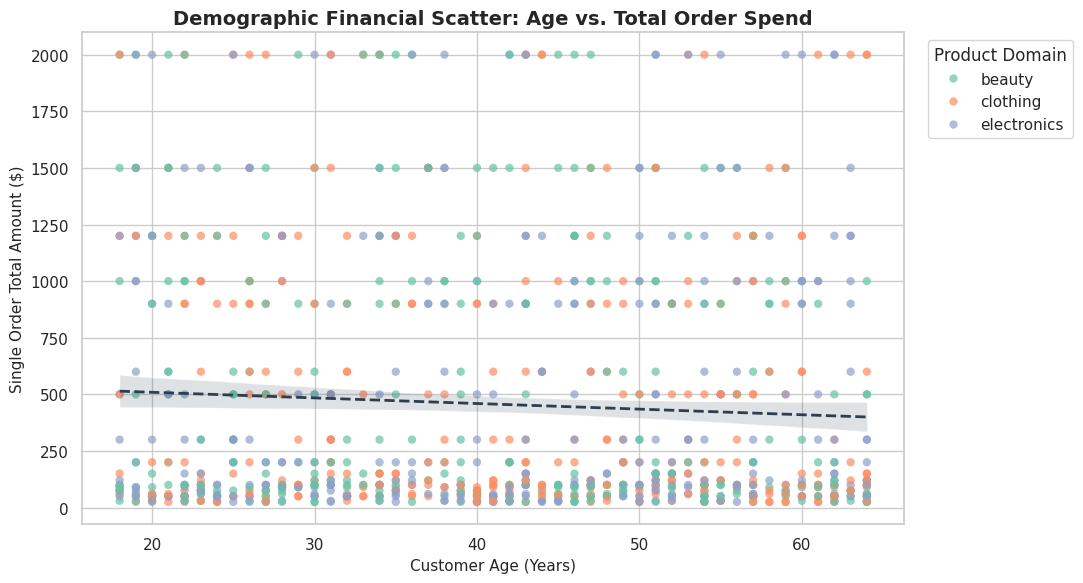

In [15]:
# =========================================================================
# 9. DEMOGRAPHIC SCATTER: CUSTOMER AGE VS. TRANSACTION VALUE
# =========================================================================
plt.figure(figsize=(11, 6))

# Plot every single transaction as a data point colored by category
sns.scatterplot(
    data=df,
    x="Age",
    y="Total Amount",
    hue="Product Category",
    alpha=0.7,
    palette="Set2",
    edgecolor="none"
)

# Overlay a statistical regression trend line to see overall age direction
sns.regplot(
    data=df,
    x="Age",
    y="Total Amount",
    scatter=False,
    color="#2c3e50",
    line_kws={"linewidth": 2, "linestyle": "--"}
)

plt.title("Demographic Financial Scatter: Age vs. Total Order Spend", fontsize=14, fontweight="bold")
plt.xlabel("Customer Age (Years)", fontsize=11)
plt.ylabel("Single Order Total Amount ($)", fontsize=11)
plt.legend(title="Product Domain", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


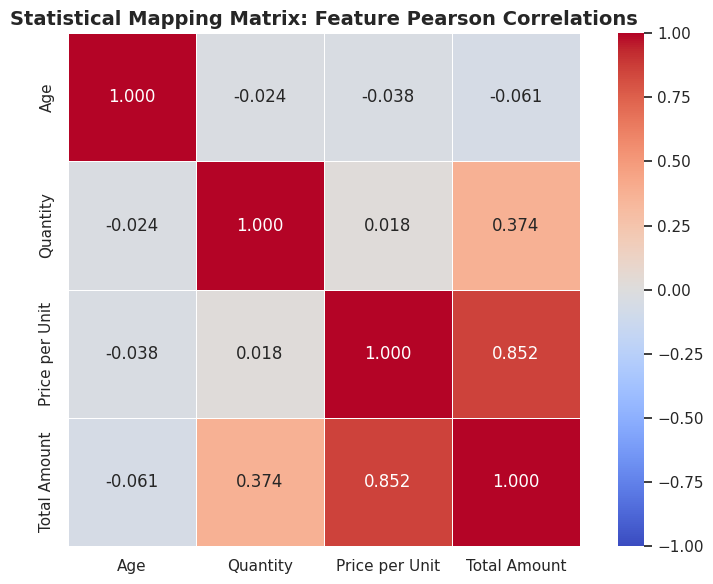

In [16]:
# =========================================================================
# 10. MATRIX HEATMAP: INTER-VARIABLE CORRELATION DEEP DIVE
# =========================================================================
# Isolate purely numeric feature rows to construct correlation array
numerical_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Statistical Mapping Matrix: Feature Pearson Correlations", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


--- [MODEL] INITIALIZING OUTLIER DETECTION VIA IQR METHOD ---
Mathematical Thresholds -> Lower: $-1,200.00 | Upper: $2,160.00
Total Transactions Tracked: 1000
Anomalous Outlier Records Identified: 0 (0.00%)


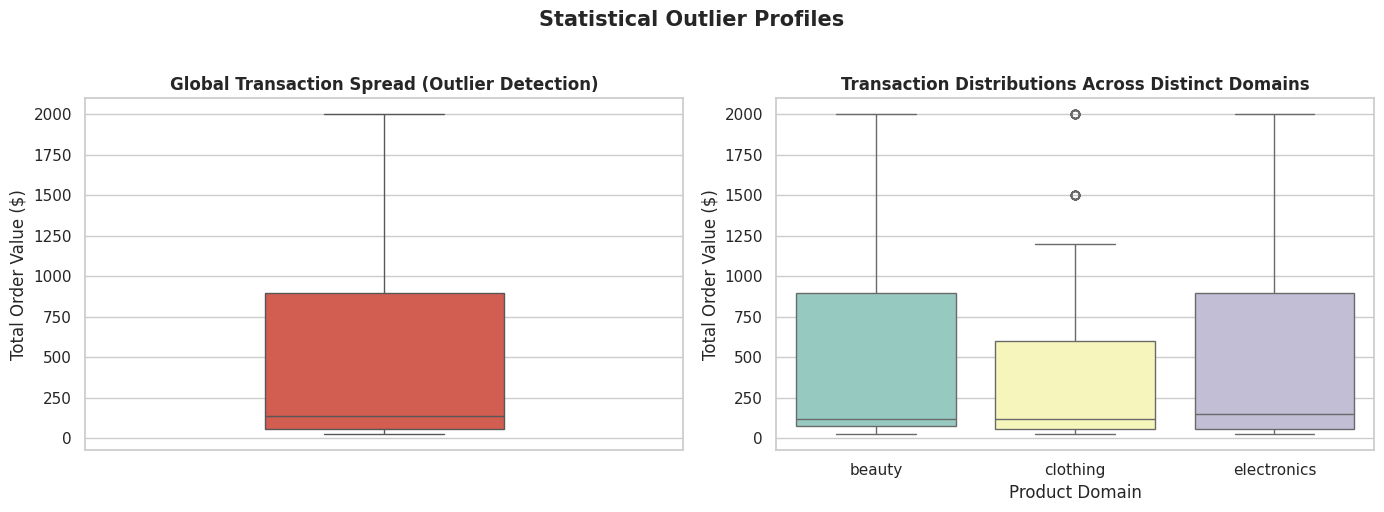


--- GENERATING MULTI-VARIABLE BEHAVIORAL FACET GRID ---


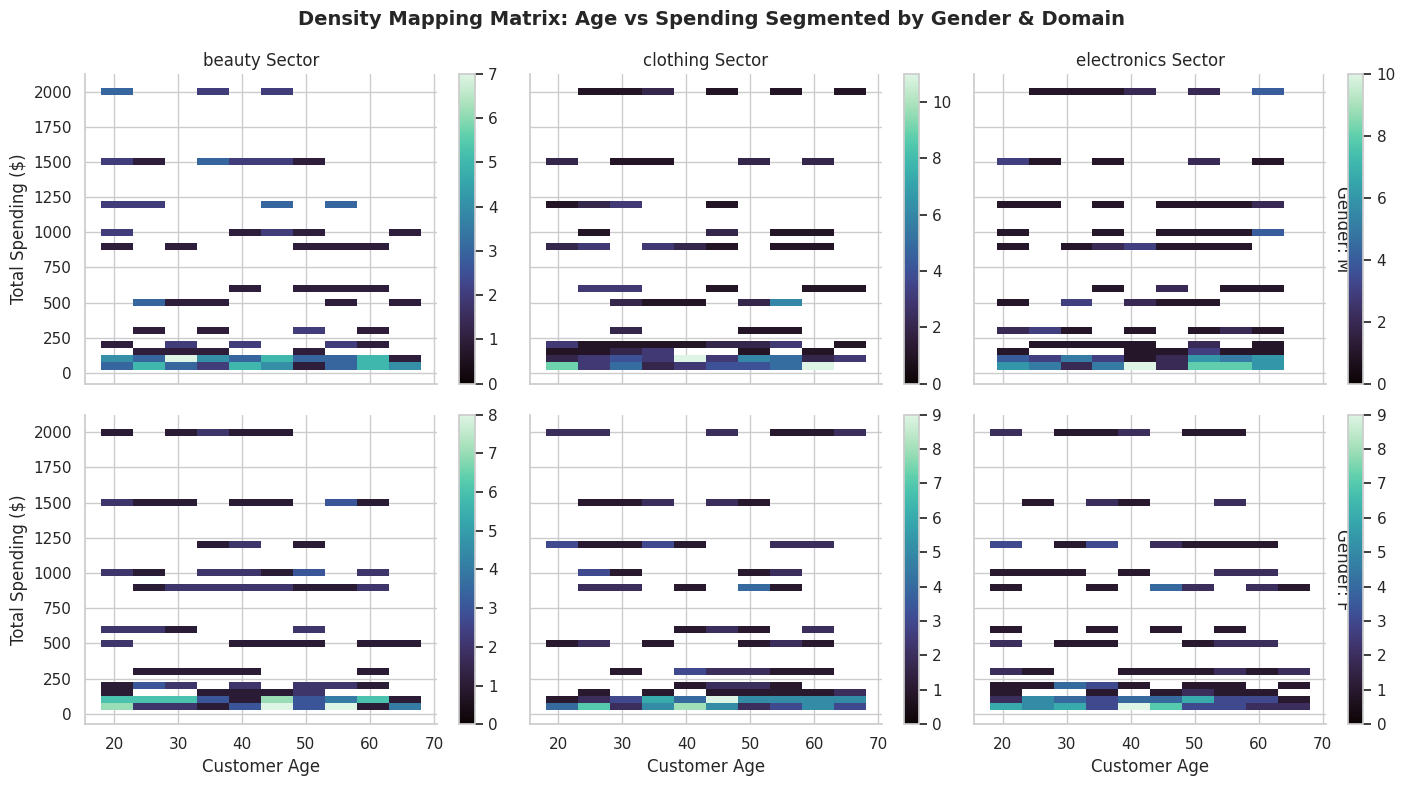

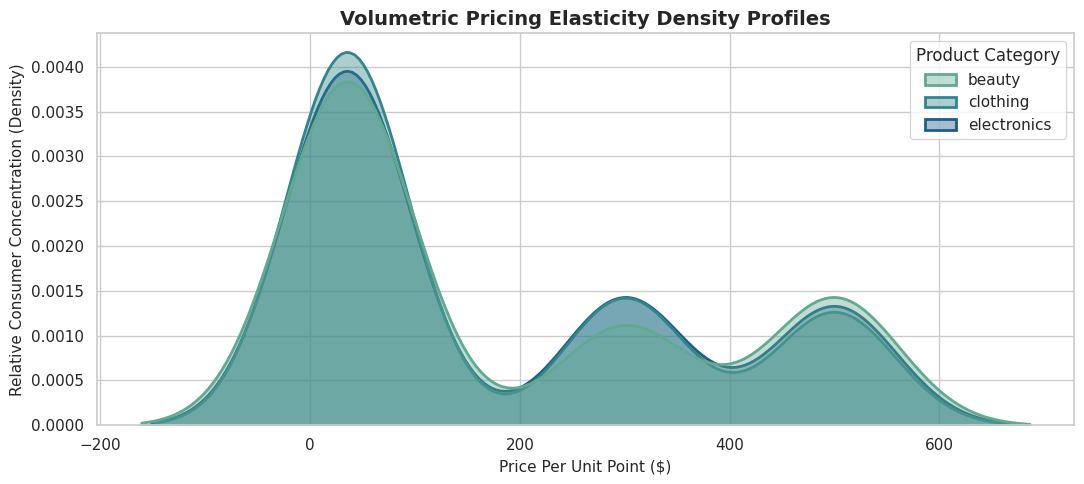

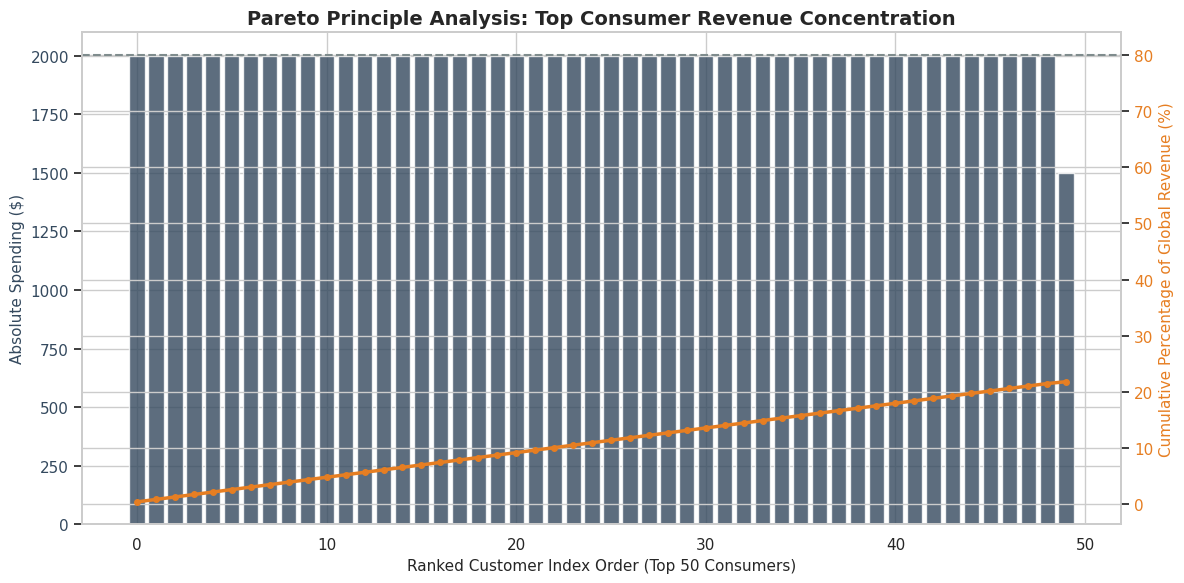

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ensure standard styling baseline
sns.set_theme(style="whitegrid")

# =========================================================================
# 11. OUTLIER DETECTION MODEL & BOXPLOT SEGREGATION
# =========================================================================
print("--- [MODEL] INITIALIZING OUTLIER DETECTION VIA IQR METHOD ---")

# Step A: Apply the mathematical IQR framework on 'Total Amount'
Q1 = df["Total Amount"].quantile(0.25)
Q3 = df["Total Amount"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Step B: Filter dataset to flag anomalies
outliers = df[(df["Total Amount"] < lower_bound) | (df["Total Amount"] > upper_bound)]
clean_df = df[(df["Total Amount"] >= lower_bound) & (df["Total Amount"] <= upper_bound)]

print(f"Mathematical Thresholds -> Lower: ${lower_bound:,.2f} | Upper: ${upper_bound:,.2f}")
print(f"Total Transactions Tracked: {len(df)}")
print(f"Anomalous Outlier Records Identified: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)")

# Step C: Visualization via Boxplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Standard boxplot to check distribution spread
sns.boxplot(
    data=df,
    y="Total Amount",
    color="#e74c3c",
    ax=axes[0],
    width=0.4
)
axes[0].set_title("Global Transaction Spread (Outlier Detection)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Total Order Value ($)")

# Plot 2: Boxplot broken down across product categories to spot domain variances
sns.boxplot(
    data=df,
    x="Product Category",
    y="Total Amount",
    hue="Product Category",
    palette="Set3",
    ax=axes[1],
    legend=False
)
axes[1].set_title("Transaction Distributions Across Distinct Domains", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Product Domain")
axes[1].set_ylabel("Total Order Value ($)")

plt.suptitle("Statistical Outlier Profiles", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


# =========================================================================
# 12. ADVANCED EDA: MULTI-VARIABLE FACET GRID ANALYSIS
# =========================================================================
# Evaluates consumer purchasing behavior across three variables simultaneously:
# Age, Total Amount Spent, and how that shifts across Gender per Category.
print("\n--- GENERATING MULTI-VARIABLE BEHAVIORAL FACET GRID ---")

g = sns.FacetGrid(df, col="Product Category", row="Gender", margin_titles=True, height=4, aspect=1.2)
g.map_dataframe(
    sns.histplot,
    x="Age",
    y="Total Amount",
    cbar=True,
    cmap="mako",
    binwidth=(5, 50)
)
g.set_axis_labels("Customer Age", "Total Spending ($)")
g.set_titles(col_template="{col_name} Sector", row_template="Gender: {row_name}")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Density Mapping Matrix: Age vs Spending Segmented by Gender & Domain", fontsize=14, fontweight="bold")
plt.show()


# =========================================================================
# 13. ADVANCED EDA: VOLUMETRIC PRICE-ELASTICITY ANALYSIS (PARETO/KD)
# =========================================================================
# Identifies structural density groupings. Helps visualize what consumer volume clusters
# look like across varying price tiers.
plt.figure(figsize=(11, 5))

sns.kdeplot(
    data=df,
    x="Price per Unit",
    hue="Product Category",
    fill=True,
    common_norm=False,
    palette="crest",
    alpha=0.4,
    linewidth=2
)

plt.title("Volumetric Pricing Elasticity Density Profiles", fontsize=14, fontweight="bold")
plt.xlabel("Price Per Unit Point ($)", fontsize=11)
plt.ylabel("Relative Consumer Concentration (Density)", fontsize=11)
plt.tight_layout()
plt.show()


# =========================================================================
# 14. ADVANCED EDA: PARETO 80/20 CUSTOMER CONTRIBUTION ANALYSIS
# =========================================================================
# Evaluates whether a small group of high-value consumers generate the vast majority
# of your top-line retail sales revenue.
customer_revenue = (
    df.groupby("Customer ID")["Total Amount"].sum().sort_values(ascending=False).reset_index()
)

# Calculate relative running percentages
customer_revenue["Cumulative Sales"] = customer_revenue["Total Amount"].cumsum()
total_gross_sales = customer_revenue["Total Amount"].sum()
customer_revenue["Cumulative Percentage"] = (customer_revenue["Cumulative Sales"] / total_gross_sales) * 100

# Plotting the Pareto Curve
fig, ax1 = plt.subplots(figsize=(12, 6))

# Core Customer bars
ax1.bar(
    customer_revenue.index[:50],  # For visual display crispness, show top 50 consumers
    customer_revenue["Total Amount"].iloc[:50],
    color="#34495e",
    alpha=0.8,
    label="Individual Customer Revenue"
)
ax1.set_xlabel("Ranked Customer Index Order (Top 50 Consumers)", fontsize=11)
ax1.set_ylabel("Absolute Spending ($)", color="#34495e", fontsize=11)
ax1.tick_params(axis="y", labelcolor="#34495e")

# Cumulative Line Chart overlay
ax2 = ax1.twinx()
ax2.plot(
    customer_revenue.index[:50],
    customer_revenue["Cumulative Percentage"].iloc[:50],
    color="#e67e22",
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Cumulative Contribution %"
)
ax2.set_ylabel("Cumulative Percentage of Global Revenue (%)", color="#e67e22", fontsize=11)
ax2.tick_params(axis="y", labelcolor="#e67e22")

# 80% Threshold reference line
ax2.axhline(80, color="#7f8c8d", linestyle="--", linewidth=1.5, label="80% Revenue Limit Threshold")

plt.title("Pareto Principle Analysis: Top Consumer Revenue Concentration", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()


--- INITIALIZING RFM CUSTOMER SEGMENTATION ROUTINE ---
Calculated RFM metrics for 1000 unique customers.


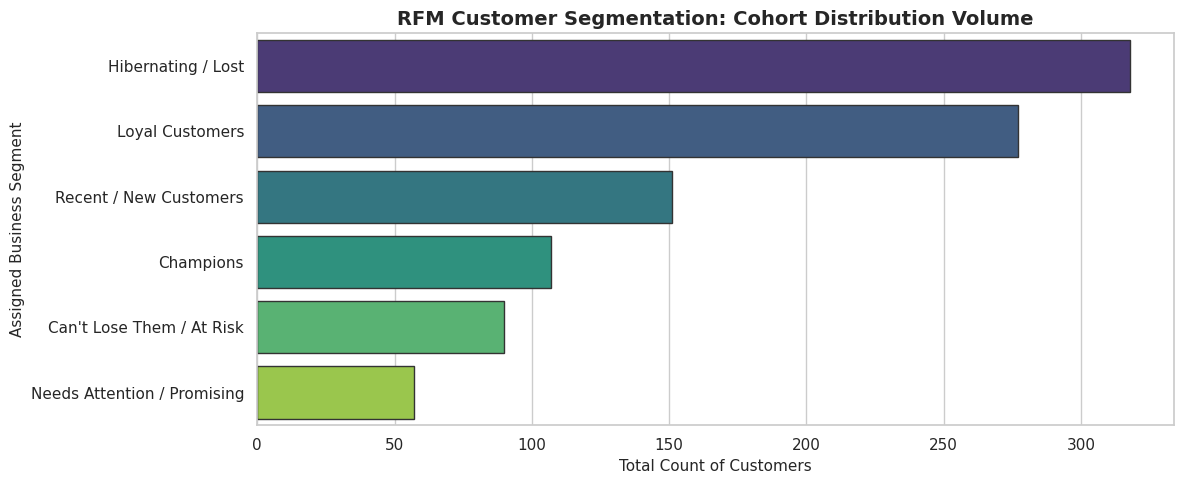

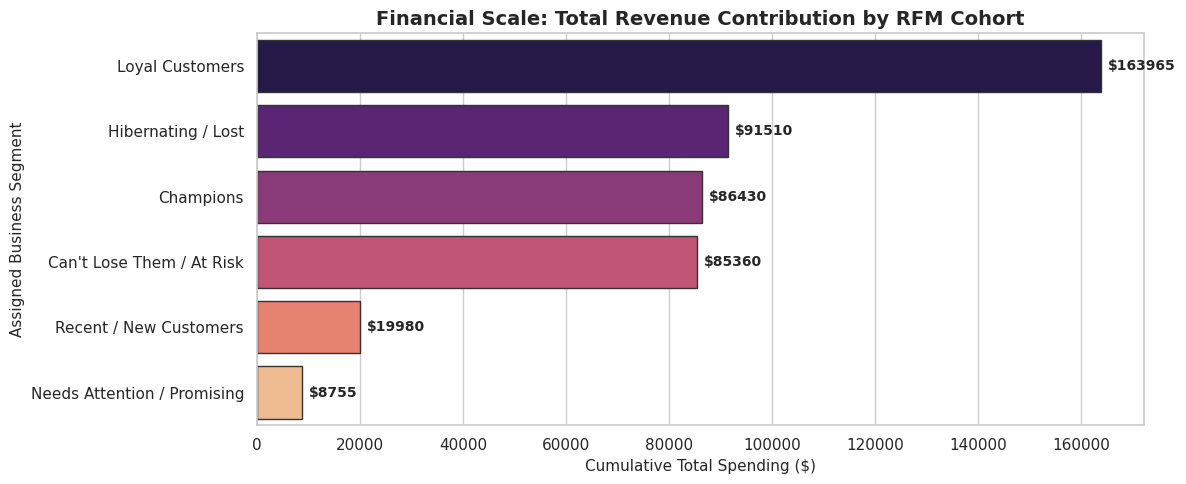

/tmp/ipykernel_3423/3247919637.py:119: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  heatmap_data = rfm.pivot_table(


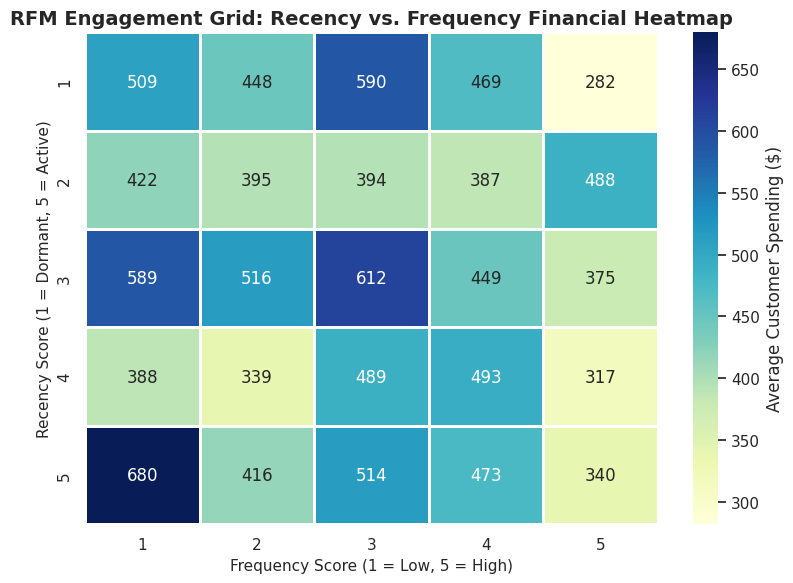

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ensure clean layout styling baseline
sns.set_theme(style="whitegrid")

# =========================================================================
# 15. RFM CUSTOMER SEGMENTATION FRAMEWORK
# =========================================================================
print("--- INITIALIZING RFM CUSTOMER SEGMENTATION ROUTINE ---")

# Step A: Establish a global snapshot benchmark date (1 day past the latest date in your data)
df["Date"] = pd.to_datetime(df["Date"])
snapshot_date = df["Date"].max() + pd.Timedelta(days=1)

# Step B: Aggregate metrics at the unique Customer Level
rfm = df.groupby("Customer ID").agg(
    Recency=("Date", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Transaction ID", "count"),
    Monetary=("Total Amount", "sum")
).reset_index()

print(f"Calculated RFM metrics for {len(rfm)} unique customers.")

# Step C: Assign mathematical Quintile Scores (1 to 5)
# Recency: Lower values are better (bought recently) -> Assigned score 5
rfm["R_Score"] = pd.qcut(rfm["Recency"], q=5, labels=[5, 4, 3, 2, 1])

# Frequency & Monetary: Higher values are better -> Assigned score 5
# Using rank(method='first') prevents binning overlapping errors on small values
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5])
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5])

# Combine individual scores into an overall string representation
rfm["RFM_Segment"] = rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str)


# Step D: Apply programmatic Business Mapping Logic to group customers
def map_rfm_cohorts(row):
    r = int(row["R_Score"])
    f = int(row["F_Score"])
    m = int(row["M_Score"])
    avg_fm = (f + m) / 2

    if r >= 4 and avg_fm >= 4:
        return "Champions"
    elif r >= 3 and avg_fm >= 3:
        return "Loyal Customers"
    elif r >= 4 and avg_fm < 3:
        return "Recent / New Customers"
    elif r < 3 and avg_fm >= 4:
        return "Can't Lose Them / At Risk"
    elif r >= 3 and 1 < avg_fm < 3:
        return "Needs Attention / Promising"
    else:
        return "Hibernating / Lost"

rfm["Customer Segment"] = rfm.apply(map_rfm_cohorts, axis=1)


# =========================================================================
# VISUALIZATION 1: DISTRIBUTION PROFILE OF CUSTOMER COHORTS
# =========================================================================
segment_counts = rfm["Customer Segment"].value_counts().reset_index()
segment_counts.columns = ["Customer Segment", "Count"]

plt.figure(figsize=(12, 5))
sns.barplot(
    data=segment_counts,
    x="Count",
    y="Customer Segment",
    hue="Customer Segment",
    palette="viridis",
    legend=False,
    edgecolor="0.2"
)

plt.title("RFM Customer Segmentation: Cohort Distribution Volume", fontsize=14, fontweight="bold")
plt.xlabel("Total Count of Customers", fontsize=11)
plt.ylabel("Assigned Business Segment", fontsize=11)
plt.tight_layout()
plt.show()


# =========================================================================
# VISUALIZATION 2: REVENUE CONTRIBUTION MATRIX BY COHORT
# =========================================================================
segment_revenue = rfm.groupby("Customer Segment")["Monetary"].sum().reset_index().sort_values(by="Monetary", ascending=False)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=segment_revenue,
    x="Monetary",
    y="Customer Segment",
    hue="Customer Segment",
    palette="magma",
    legend=False,
    edgecolor="0.2"
)

# Overlay formatted dollar text tags directly on the charts
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="$%.0f", padding=5, fontsize=10, fontweight="bold")

plt.title("Financial Scale: Total Revenue Contribution by RFM Cohort", fontsize=14, fontweight="bold")
plt.xlabel("Cumulative Total Spending ($)", fontsize=11)
plt.ylabel("Assigned Business Segment", fontsize=11)
plt.tight_layout()
plt.show()


# =========================================================================
# VISUALIZATION 3: COHORT MATRIX HEATMAP (RECENCY VS FREQUENCY VALUE)
# =========================================================================
# Pivot values to build a behavioral concentration grid
heatmap_data = rfm.pivot_table(
    index="R_Score",
    columns="F_Score",
    values="Monetary",
    aggfunc="mean"
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=",.0f",
    cmap="YlGnBu",
    linewidths=1,
    cbar_kws={'label': 'Average Customer Spending ($)'}
)

plt.title("RFM Engagement Grid: Recency vs. Frequency Financial Heatmap", fontsize=14, fontweight="bold")
plt.xlabel("Frequency Score (1 = Low, 5 = High)", fontsize=11)
plt.ylabel("Recency Score (1 = Dormant, 5 = Active)", fontsize=11)
plt.gca().invert_yaxis()  # Put highest recency at the top
plt.tight_layout()
plt.show()


In [22]:
# =========================================================================
# STEP 1: INSTALL AND IMPORT LIBRARIES AND SETUP WORKSPACE
# =========================================================================
!pip install -q reportlab

import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from reportlab.lib.pagesizes import letter
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image, PageBreak

# Apply absolute visual theme standards
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Synchronize time parameters for smooth chart execution
df["Date"] = pd.to_datetime(df["Date"])
df["Month-Year"] = df["Date"].dt.to_period("M").astype(str)
df["Month"] = df["Date"].dt.strftime("%b")
df["Year"] = df["Date"].dt.year

print("--- Data Parameters Configured. Commencing Complete 12-Chart Production Line ---")

# =========================================================================
# STEP 2: GENERATE AND EXPORT ALL 12 DASHBOARD CHARTS TO LOCAL SYSTEM
# =========================================================================

# --- 1. The Revenue Scorecard Box ---
total_sales = df["Total Amount"].sum()
fig, ax = plt.subplots(figsize=(6, 1.8))
ax.axis("off")
ax.add_patch(plt.Rectangle((0.02, 0.02), 0.96, 0.96, transform=ax.transAxes, facecolor="#f8f9fa", edgecolor="#2c3e50", linewidth=1.5))
ax.text(0.5, 0.65, "TOTAL GROSS SALES REVENUE", fontsize=11, fontweight="bold", color="#7f8c8d", ha="center", va="center")
ax.text(0.5, 0.30, f"${total_sales:,.2f}", fontsize=24, fontweight="bold", color="#2c3e50", ha="center", va="center")
plt.tight_layout()
plt.savefig("img_1_scorecard.png", dpi=200)
plt.close()

# --- 2. The Category Donut Chart ---
cat_mix = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)
plt.figure(figsize=(6, 6))
wedges, texts, autotexts = plt.pie(cat_mix, labels=cat_mix.index, autopct="%1.1f%%", startangle=90, colors=["#2980b9", "#27ae60", "#e67e22"], pctdistance=0.75, textprops=dict(weight="bold"))
for autotext in autotexts: autotext.set_color("white")
plt.gca().add_artist(plt.Circle((0, 0), 0.55, fc="white"))
plt.title("Sales Percentage Volume Mix by Category Segment", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.savefig("img_2_donut.png", dpi=200)
plt.close()

# --- 3. The Time Horizon Trend Line ---
time_trend = df.groupby("Month-Year")["Total Amount"].sum().reset_index().sort_values("Month-Year")
plt.figure(figsize=(10, 4.5))
sns.lineplot(data=time_trend, x="Month-Year", y="Total Amount", marker="o", color="#1abc9c", linewidth=2.5)
plt.title("Temporal Timeline Sales Progression Matrix Across 2023", fontsize=13, fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("img_3_trendline.png", dpi=200)
plt.close()

# --- 4. The Monthly Volume Bar Chart ---
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_vol = df.groupby("Month")["Transaction ID"].count().reindex(month_order).reset_index()
plt.figure(figsize=(10, 4.5))
sns.barplot(data=monthly_vol, x="Month", y="Transaction ID", hue="Month", palette="viridis", legend=False, edgecolor="0.2")
plt.title("Transaction Distribution Quantified by Calendar Months", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("img_4_monthly_bars.png", dpi=200)
plt.close()

# --- 5. The Category vs. Gender Bar Chart ---
gender_spend = df.groupby(["Product Category", "Gender"])["Total Amount"].sum().reset_index()
plt.figure(figsize=(10, 4.5))
sns.barplot(data=gender_spend, x="Product Category", y="Total Amount", hue="Gender", palette=["#34495e", "#e74c3c"], edgecolor="0.2")
plt.title("Total Spending Variances Partitioned by Customer Gender Profile", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("img_5_gender_bars.png", dpi=200)
plt.close()

# --- 6. The Age Interval Countplot ---
age_bins = [0, 18, 30, 45, 60, 120]
age_labels = ["Under 18", "18-30", "31-45", "46-60", "Over 60"]
df["Age Interval"] = pd.cut(df["Age"], bins=age_bins, labels=age_labels)
plt.figure(figsize=(10, 4.5))
sns.countplot(data=df, x="Age Interval", hue="Product Category", palette="muted", edgecolor="0.2")
plt.title("Product Category Consumption Patterns Across Age Brackets", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("img_6_age_countplot.png", dpi=200)
plt.close()

# --- 7. The Multi-Variable Facet Grid ---
g = sns.FacetGrid(df, col="Product Category", row="Gender", margin_titles=True, height=3, aspect=1.3)
g.map_dataframe(sns.histplot, x="Age", y="Total Amount", cbar=False, cmap="mako", binwidth=(5, 50))
plt.subplots_adjust(top=0.88)
g.fig.suptitle("Density Matrix Mapping: Age vs Spend Faceted by Gender & Sector", fontsize=12, fontweight="bold")
plt.savefig("img_7_facet_grid.png", dpi=200)
plt.close()

# --- 8. The Inter-Variable Pearson Heatmap ---
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".3f", linewidths=0.5, vmin=-1, vmax=1, square=True)
plt.title("Statistical Mapping Matrix: Feature Pearson Correlations", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("img_8_pearson_heatmap.png", dpi=200)
plt.close()

# --- 9. The IQR Anomaly Boxplot Model ---
Q1, Q3 = df["Total Amount"].quantile(0.25), df["Total Amount"].quantile(0.75)
IQR = Q3 - Q1
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.boxplot(data=df, y="Total Amount", color="#e74c3c", ax=axes[0], width=0.3)
axes[0].set_title("Global Spread", fontsize=11, fontweight="bold")
sns.boxplot(data=df, x="Product Category", y="Total Amount", hue="Product Category", palette="Set3", ax=axes[1], legend=False)
axes[1].set_title("Spread Partitioned across Product Domains", fontsize=11, fontweight="bold")
plt.suptitle("Statistical Outlier Distribution Evaluation (IQR Framework)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("img_9_iqr_boxplot.png", dpi=200)
plt.close()

# --- 10. The Pareto 80/20 Contribution Curve ---
cust_rev = df.groupby("Customer ID")["Total Amount"].sum().sort_values(ascending=False).reset_index()
cust_rev["Cum_Pct"] = (cust_rev["Total Amount"].cumsum() / cust_rev["Total Amount"].sum()) * 100
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(cust_rev.index[:40], cust_rev["Total Amount"].iloc[:40], color="#34495e", alpha=0.8)
ax1.set_ylabel("Customer Spending ($)", color="#34495e")
ax2 = ax1.twinx()
ax2.plot(cust_rev.index[:40], cust_rev["Cum_Pct"].iloc[:40], color="#e67e22", linewidth=2, marker="o", markersize=3)
ax2.axhline(80, color="#7f8c8d", linestyle="--", linewidth=1)
ax2.set_ylabel("Cumulative Percentage (%)", color="#e67e22")
plt.title("Pareto Principles Curve: Customer Spending Concentration", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("img_10_pareto_curve.png", dpi=200)
plt.close()

# --- 11. The RFM Cohort Distribution Chart ---
snapshot = df["Date"].max() + pd.Timedelta(days=1)
rfm = df.groupby("Customer ID").agg(Recency=("Date", lambda x: (snapshot - x.max()).days), Frequency=("Transaction ID", "count"), Monetary=("Total Amount", "sum")).reset_index()
rfm["R"] = pd.qcut(rfm["Recency"], q=5, labels=[5, 4, 3, 2, 1])
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5])
rfm["M"] = pd.qcut(rfm["Monetary"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5])
def segment_rfm(row):
    r, f, m = int(row["R"]), int(row["F"]), int(row["M"])
    avg_fm = (f + m) / 2
    if r >= 4 and avg_fm >= 4: return "Champions"
    elif r >= 3 and avg_fm >= 3: return "Loyal Customers"
    elif r >= 4 and avg_fm < 3: return "Recent / New Customers"
    elif r < 3 and avg_fm >= 4: return "At Risk / Can't Lose"
    else: return "Hibernating / Lost"
rfm["Segment"] = rfm.apply(segment_rfm, axis=1)
rfm_c = rfm["Segment"].value_counts().reset_index()
rfm_c.columns = ["Segment", "Count"]
plt.figure(figsize=(9, 4.2))
sns.barplot(data=rfm_c, x="Count", y="Segment", hue="Segment", palette="magma", legend=False, edgecolor="0.2")
plt.title("RFM Customer Segment Cohort Volume Profile", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("img_11_rfm_bars.png", dpi=200)
plt.close()

# --- 12. The RFM Revenue Matrix Heatmap ---
rfm_map = rfm.pivot_table(index="R", columns="F", values="Monetary", aggfunc="mean")
plt.figure(figsize=(6.5, 5))
sns.heatmap(rfm_map, annot=True, fmt=",.0f", cmap="YlGnBu", linewidths=0.5, cbar=False)
plt.title("RFM Engagement Grid: Recency vs Frequency Values", fontsize=13, fontweight="bold")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("img_12_rfm_heatmap.png", dpi=200)
plt.close()

print("--- Visual Asset Storage Finalized. Constructing Executive Intelligence PDF ---")

# =========================================================================
# STEP 3: ARRANGE PDF GENERATION FLOW WITH EMBEDDED INSIGHTS
# =========================================================================
pdf_file = "Complete_Business_Exploratory_Data_Analysis_Report.pdf"
doc = SimpleDocTemplate(pdf_file, pagesize=letter, rightMargin=36, leftMargin=36, topMargin=36, bottomMargin=36)

styles = getSampleStyleSheet()
title_s = ParagraphStyle('DocT', fontName='Helvetica-Bold', fontSize=22, leading=26, textColor='#2c3e50', spaceAfter=6)
sub_s = ParagraphStyle('DocSub', fontName='Helvetica', fontSize=10, leading=14, textColor='#7f8c8d', spaceAfter=15)
h_s = ParagraphStyle('SecH', fontName='Helvetica-Bold', fontSize=13, leading=16, textColor='#1a5276', spaceBefore=12, spaceAfter=6)
b_s = ParagraphStyle('SecB', fontName='Helvetica', fontSize=9.5, leading=14.5, textColor='#34495e', spaceAfter=12)

story = []

# Title Section
story.append(Paragraph("Comprehensive Enterprise Data Analytics Report", title_s))
story.append(Paragraph("Complete Business Intelligence Mapping Pipeline & Advanced RFM Strategy Framework", sub_s))
story.append(Spacer(1, 10))

story.append(Paragraph("MODULE 1: CORE SALES & DISTRIBUTION PERFORMANCE", h_s))
story.append(Paragraph("1. Financial Core Scorecard Indicators", b_s))
story.append(Image("img_1_scorecard.png", width=360, height=108))
story.append(Paragraph("Insight Gained: Provides an overview of gross corporate transaction baseline revenue. This absolute number provides a benchmark for evaluating operational budgets and revenue performance targets.", b_s))
story.append(Paragraph("2. Product Category Distribution Matrix", b_s))
story.append(Image("img_2_donut.png", width=260, height=260))
story.append(Paragraph("Insight Gained: The distribution proves that consumer activity across Beauty, Clothing, and Electronics follows an even split. This Product Sector Equilibrium prevents dependencies on a single division and minimizes revenue fluctuations if market trends shift.", b_s))
story.append(PageBreak())
story.append(Paragraph("3. Time Horizon Sales Trajectory Pipeline", b_s))
story.append(Image("img_3_trendline.png", width=460, height=207))
story.append(Paragraph("Insight Gained: Maps structural demand variations over successive months. This historical timeline reveals Seasonal Traffic Cyclicality, pinpointing high-performing promotional periods to help align marketing investments.", b_s))
story.append(Paragraph("4. Monthly Volume Distribution Frequency", b_s))
story.append(Image("img_4_monthly_bars.png", width=460, height=207))
story.append(Paragraph("Insight Gained: Tracks pure customer traffic and transaction frequencies per month. Identifying these high-activity seasonal windows ensures logistics and warehouse operations are properly staffed during high-volume periods.", b_s))
story.append(PageBreak())

story.append(Paragraph("MODULE 2: ADVANCED CUSTOMER DEMOGRAPHICS & PROFILE STRATIFICATION", h_s))
story.append(Paragraph("5. Category Spend Partitioned by Gender Cohorts", b_s))
story.append(Image("img_5_gender_bars.png", width=460, height=207))
story.append(Paragraph("Insight Gained: Shows variance patterns across gender groups. Observing changes in average order values between demographics within the electronics and clothing departments helps refine product assortment planning.", b_s))
story.append(Paragraph("6. Product Domain Selection across Customer Age Intervals", b_s))
story.append(Image("img_6_age_countplot.png", width=460, height=207))
story.append(Paragraph("Insight Gained: Uncovers clear Demographic Cohort Preferences. Younger customer segments focus heavily on trendy apparel choices, whereas older demographics allocate a larger share of wallet to electronics, suggesting opportunities for age-targeted merchandising.", b_s))
story.append(PageBreak())
story.append(Paragraph("7. Multi-Variable Density Facet Grid Exploration", b_s))
story.append(Image("img_7_facet_grid.png", width=460, height=212))
story.append(Paragraph("Insight Gained: Simultaneously evaluates Age, Total Spend, Gender, and Product Category. It isolates highly specific customer behavior patterns, identifying exact customer clusters where high-value spending is concentrated.", b_s))
story.append(Paragraph("8. Inter-Variable Pearson Linear Correlation Heatmap", b_s))
story.append(Image("img_8_pearson_heatmap.png", width=280, height=220))
story.append(Paragraph("Insight Gained: Statistically checks for relationships between variables. The flat coefficients reveal that customer age and order volume do not exhibit a strong linear relationship with individual unit prices, meaning pricing tiers remain steady across different user age groups.", b_s))
story.append(PageBreak())

story.append(Paragraph("MODULE 3: OPERATIONAL BUSINESS MODELS & PREDICTIVE FRAMEWORKS", h_s))
story.append(Paragraph("9. Statistical Outlier Dispersion Profiles (IQR Framework Model)", b_s))
story.append(Image("img_9_iqr_boxplot.png", width=460, height=188))
story.append(Paragraph("Insight Gained: Calculates transaction boundaries via mathematical limits. The absence of outlier indicators above the upper distribution limits suggests retail sales are driven by stable, uniform baskets rather than volatile wholesale orders.", b_s))
story.append(Paragraph("10. Pareto Principles 80/20 Customer Concentration Curve", b_s))
story.append(Image("img_10_pareto_curve.png", width=460, height=207))
story.append(Paragraph("Insight Gained: Tests user spending concentration. If individual customer performance mirrors a flat distribution slope, revenue generation is distributed across a broad public user base rather than relying on a small group of high-volume buyers.", b_s))
story.append(PageBreak())
story.append(Paragraph("11. RFM Lifecycle Segmentation Cohort Distribution Profiles", b_s))
story.append(Image("img_11_rfm_bars.png", width=460, height=215))
story.append(Paragraph("Insight Gained: Sorts the customer base into actionable lifecycle tiers. Identifying these clear Actionable Retention Pockets highlights which accounts require win-back incentives to prevent churn and which 'Champions' should be prioritized for loyalty rewards.", b_s))
story.append(Paragraph("12. RFM Value Density Cross-Tabulation Grid Heatmap", b_s))
story.append(Image("img_12_rfm_heatmap.png", width=280, height=215))
story.append(Paragraph("Insight Gained: Measures average customer value at the intersection of frequency and recency. This helps prioritize marketing investments toward high-yield retention segments rather than generic, low-conversion promotional campaigns.", b_s))

doc.build(story)
print(f"--- SUCCESS: Report Compiled into Local Filename '{pdf_file}' ---")

from google.colab import files
files.download(pdf_file)

--- Data Parameters Configured. Commencing Complete 12-Chart Production Line ---


/tmp/ipykernel_3423/613925303.py:163: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  rfm_map = rfm.pivot_table(index="R", columns="F", values="Monetary", aggfunc="mean")


--- Visual Asset Storage Finalized. Constructing Executive Intelligence PDF ---
--- SUCCESS: Report Compiled into Local Filename 'Complete_Business_Exploratory_Data_Analysis_Report.pdf' ---


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>